In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

scored = pd.read_csv("../data/processed/test_patients_scored.csv", low_memory=False)
print("Test patients:", len(scored), "| actual readmissions:", scored["readmitted_30d"].sum())

COST_PER_READMISSION = 15200        # average cost of one readmission (AHRQ, US)
PROGRAMME_COST_PER_PATIENT = 500    # cost to enrol one patient in follow-up care
EFFECTIVENESS = 0.20                # programme prevents 20% of readmissions among enrolled patients

Test patients: 13998 | actual readmissions: 1257


In [2]:
def savings_table(df, cost_readmit, cost_patient, effectiveness):
    ranked = df.sort_values("risk_score", ascending=False)      # riskiest patients first
    actual = ranked["readmitted_30d"].values
    n = len(ranked)
    scale = 10_000 / n                                          # report everything per 10,000 discharges

    rows = []
    for pct in list(range(1, 20)) + list(range(20, 101, 5)):
        enrolled = int(round(n * pct / 100))                    # how many patients we enrol
        caught = actual[:enrolled].sum()                        # real readmissions among them
        prevented = caught * effectiveness * scale              # how many the programme prevents
        savings = prevented * cost_readmit                      # money saved
        cost = enrolled * scale * cost_patient                  # money spent
        rows.append({"pct_enrolled": pct,
                     "patients_enrolled_per_10k": round(enrolled * scale),
                     "readmissions_caught_pct": round(100 * caught / actual.sum(), 1),
                     "readmissions_prevented_per_10k": round(prevented, 1),
                     "savings_usd": round(savings),
                     "programme_cost_usd": round(cost),
                     "net_savings_usd": round(savings - cost)})
    return pd.DataFrame(rows)

In [3]:
table = savings_table(scored, COST_PER_READMISSION, PROGRAMME_COST_PER_PATIENT, EFFECTIVENESS)
best = table.loc[table["net_savings_usd"].idxmax()]

print(f"Best: enrol the top {best['pct_enrolled']:.0f}% riskiest patients")
print(f"Catches {best['readmissions_caught_pct']}% of readmissions, "
      f"net savings ${best['net_savings_usd']:,.0f} per 10,000 discharges")
table.iloc[[0, 4, 8, 9, 14, 19, 23, -1]]

Best: enrol the top 9% riskiest patients
Catches 22.0% of readmissions, net savings $149,336 per 10,000 discharges


,pct_enrolled,patients_enrolled_per_10k,readmissions_caught_pct,readmissions_prevented_per_10k,savings_usd,programme_cost_usd,net_savings_usd
0,1,100,3.9,7.0,106415,50007,56408
4,5,500,13.8,24.9,377883,250036,127847
8,9,900,22.0,39.4,599400,450064,149336
9,10,1000,22.9,41.1,625461,500071,125389
14,15,1500,30.9,55.6,844806,750107,94699
19,20,2000,38.9,69.9,1061980,1000143,61837
23,40,4000,62.2,111.7,1698300,1999929,-301629
35,100,10000,100.0,179.6,2729876,5000000,-2270124


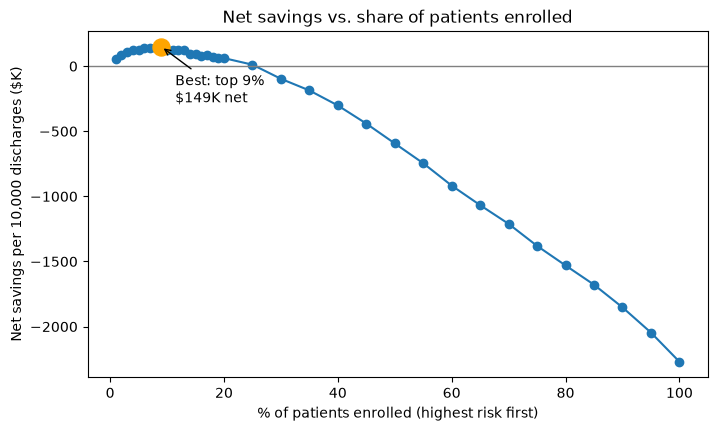

In [6]:
os.makedirs("../outputs/figures", exist_ok=True)

plt.figure(figsize=(8, 4.5))
plt.plot(table["pct_enrolled"], table["net_savings_usd"] / 1000, marker="o")
plt.axhline(0, color="grey", linewidth=1)
plt.scatter(best["pct_enrolled"], best["net_savings_usd"] / 1000, color="orange", s=150, zorder=3)
plt.annotate(f"Best: top {best['pct_enrolled']:.0f}%\n${best['net_savings_usd']/1000:,.0f}K net",
             (best["pct_enrolled"], best["net_savings_usd"] / 1000),
             xytext=(10, -40), textcoords="offset points", arrowprops=dict(arrowstyle="->"))
plt.xlabel("% of patients enrolled (highest risk first)")
plt.ylabel("Net savings per 10,000 discharges ($K)")
plt.title("Net savings vs. share of patients enrolled")
plt.savefig("../outputs/figures/savings_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
sens = []
for eff in [0.10, 0.20, 0.30]:
    for cost_pp in [250, 500, 1000]:
        t = savings_table(scored, COST_PER_READMISSION, cost_pp, eff)
        r = t.loc[t["net_savings_usd"].idxmax()]
        worth_it = r["net_savings_usd"] > 0
        sens.append({"effectiveness": f"{int(eff * 100)}%",
                     "cost_per_patient": cost_pp,
                     "best_pct_enrolled": int(r["pct_enrolled"]) if worth_it else 0,
                     "net_savings_per_10k": int(r["net_savings_usd"]) if worth_it else 0})
sens = pd.DataFrame(sens)

print("Net savings per 10K discharges ($):")
print(sens.pivot(index="effectiveness", columns="cost_per_patient", values="net_savings_per_10k"))
print("\nBest % of patients to enrol:")
print(sens.pivot(index="effectiveness", columns="cost_per_patient", values="best_pct_enrolled"))

Net savings per 10K discharges ($):
cost_per_patient     250     500    1000
effectiveness                           
10%                 74668    3200      0
20%                698335  149336   6401
30%               1732062  642492  91842

Best % of patients to enrol:
cost_per_patient  250   500   1000
effectiveness                     
10%                  9     1     0
20%                 40     9     1
30%                 85    25     4


In [8]:
cutoff = scored["risk_score"].quantile(0.91)              # top 9% = "high risk"
scored["flagged"] = (scored["risk_score"] >= cutoff).astype(int)

for col in ["race", "gender"]:
    g = scored.groupby(col).agg(patients=("flagged", "size"),
                                actual_rate_pct=("readmitted_30d", "mean"),
                                flagged_pct=("flagged", "mean"))
    g["caught_pct"] = scored[scored["readmitted_30d"] == 1].groupby(col)["flagged"].mean()
    g[["actual_rate_pct", "flagged_pct", "caught_pct"]] *= 100
    print(g[g["patients"] >= 200].round(1), "\n")

                 patients  actual_rate_pct  flagged_pct  caught_pct
race                                                               
AfricanAmerican      2457              9.1          8.1        15.7
Caucasian           10514              9.1          9.3        23.5
Hispanic              299              7.0          6.7        19.0
Other                 229              7.4          7.0        23.5
Unknown               401              6.5          8.5        19.2 

        patients  actual_rate_pct  flagged_pct  caught_pct
gender                                                    
Female      7434              8.6          9.8        22.8
Male        6564              9.5          8.1        21.1 



In [9]:
cutoff = scored["risk_score"].quantile(0.91)              # top 9% = "high risk"
scored["flagged"] = (scored["risk_score"] >= cutoff).astype(int)

for col in ["race", "gender"]:
    g = scored.groupby(col).agg(patients=("flagged", "size"),
                                actual_rate_pct=("readmitted_30d", "mean"),
                                flagged_pct=("flagged", "mean"))
    g["caught_pct"] = scored[scored["readmitted_30d"] == 1].groupby(col)["flagged"].mean()
    g[["actual_rate_pct", "flagged_pct", "caught_pct"]] *= 100
    print(g[g["patients"] >= 200].round(1), "\n")

                 patients  actual_rate_pct  flagged_pct  caught_pct
race                                                               
AfricanAmerican      2457              9.1          8.1        15.7
Caucasian           10514              9.1          9.3        23.5
Hispanic              299              7.0          6.7        19.0
Other                 229              7.4          7.0        23.5
Unknown               401              6.5          8.5        19.2 

        patients  actual_rate_pct  flagged_pct  caught_pct
gender                                                    
Female      7434              8.6          9.8        22.8
Male        6564              9.5          8.1        21.1 



In [10]:
scored["risk_rank_pct"] = scored["risk_score"].rank(ascending=False, pct=True).mul(100).round(1)
scored["risk_tier"] = pd.cut(scored["risk_rank_pct"], bins=[0, 9, 30, 100], labels=["High", "Medium", "Low"])

print(scored.groupby("risk_tier", observed=True)
            .agg(patients=("readmitted_30d", "size"), readmit_rate=("readmitted_30d", "mean")).round(3))

os.makedirs("../powerbi/data", exist_ok=True)
scored.drop(columns="flagged").to_csv("../powerbi/data/patient_risk_scores.csv", index=False)
table.to_csv("../powerbi/data/savings_scenarios.csv", index=False)
sens.to_csv("../powerbi/data/sensitivity_analysis.csv", index=False)
print("Saved for Power BI")

           patients  readmit_rate
risk_tier                        
High           1260         0.217
Medium         2941         0.126
Low            9791         0.062
Saved for Power BI
